# Effect of Interpolation Order on Template-Aligned Cortical MD Profiles

## Native-column MD value interpolation after volume sampling versus native-coordinate interpolation before volume sampling

This notebook is summary-only. All profile loading, validity masks,
depth-wise metrics, cross-subject metrics, fixed spatial groups, and
difference maps are computed by the Python analysis script:

`qc/archive/template_registration_comparison/interpolation_order/py/compare_o2_column_o3_coordinate.py`

The primary comparison uses 30 common ADRC subjects, both hemispheres,
21 cortical depths from white matter (`0.00`) to pial surface (`1.00`),
and the `fsaverage` template.

The notebook addresses individual-profile agreement, preservation of
cross-subject variation, dependence on spatial group size, local
spatial structure, and a supplementary O2-FS comparison.

- **O2-Column:** MD-value interpolation after native-column sampling.
- **O3-Coordinate:** Native-coordinate interpolation before MD-volume sampling.
- **O2-FS:** Standard `mri_vol2surf` volume-resampling reference; not a
  primary method in this notebook.

## Load completed Python outputs

The cells below read CSV summaries and existing map files only. They do
not load vertex-by-depth arrays and do not repeat profile generation or
surface mapping.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


PROJECT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
)
RESULTS_ROOT = Path("/mnt/newStor/paros/paros_WORK/xintong/results")
OUTPUT_ROOT = RESULTS_ROOT / "interpolation_order_comparison_fsaverage_python"
QC_ROOT = OUTPUT_ROOT / "qc"
METRICS_ROOT = OUTPUT_ROOT / "metrics"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
SUMMARY_ROOT = OUTPUT_ROOT / "summary"
SUMMARY_ROOT.mkdir(parents=True, exist_ok=True)

paired_manifest = pd.read_csv(QC_ROOT / "paired_subject_manifest.csv")
validation = pd.read_csv(QC_ROOT / "input_validation_summary.csv")
cohort_depth = pd.read_csv(METRICS_ROOT / "cohort_depth_summary.csv")
subject_depth = pd.read_csv(
    METRICS_ROOT / "subject_depth_metrics_by_subject.csv"
)
profile_metrics = pd.read_csv(METRICS_ROOT / "subject_profile_metrics.csv")
cross_subject = pd.read_csv(METRICS_ROOT / "cross_subject_metrics.csv")
variation_ratio = pd.read_csv(
    METRICS_ROOT / "method_difference_to_subject_variation.csv"
)
group_subject = pd.read_csv(
    METRICS_ROOT / "spatial_group_subject_metrics.csv"
)
group_cross = pd.read_csv(
    METRICS_ROOT / "spatial_group_cross_subject_metrics.csv"
)
spatial_structure = pd.read_csv(
    METRICS_ROOT / "spatial_structure_metrics.csv"
)
o2fs_summary = pd.read_csv(
    OUTPUT_ROOT / "supplementary/o2fs_vs_o2column_metrics.csv"
)
o2fs_regional = pd.read_csv(
    OUTPUT_ROOT / "supplementary/o2fs_vs_o2column_regional_metrics.csv"
)
decision_summary = pd.read_csv(
    SUMMARY_ROOT / "interpolation_order_summary.csv"
)

print(f"Output root: {OUTPUT_ROOT}")
print(f"Subjects: {validation.subject.nunique()}")
print(f"Subject-hemisphere QC rows: {len(validation)}")
display(paired_manifest.head())

Output root: /mnt/newStor/paros/paros_WORK/xintong/results/interpolation_order_comparison_fsaverage_python
Subjects: 30
Subject-hemisphere QC rows: 60


,subject,hemisphere,o2_available,o3_available,target_vertex_ids_shape,o2_source_vertex_ids_shape,o3_source_vertex_ids_shape,o2_weights_shape,o3_weights_shape,same_source_vertex_ids,...,o3_depths_complete,o3_sampling_order,o3_sampling_mode,o3_coordinate_indexing,o3_raw_in_bounds_pct,o3_sampled_finite_pct,o2_valid_pct,o3_valid_pct,common_valid_pct,included
0,D0007,lh,True,True,"(163842,)","(163842, 3)","(163842, 3)","(163842, 3)","(163842, 3)",True,...,False,1,nearest,0-based after subtracting 1 from transform output,100.0,100.0,91.870216,100.0,91.870216,True
1,D0007,rh,True,True,"(163842,)","(163842, 3)","(163842, 3)","(163842, 3)","(163842, 3)",True,...,False,1,nearest,0-based after subtracting 1 from transform output,100.0,100.0,92.044775,100.0,92.044775,True
2,D0050,lh,True,True,"(163842,)","(163842, 3)","(163842, 3)","(163842, 3)","(163842, 3)",True,...,False,1,nearest,0-based after subtracting 1 from transform output,100.0,100.0,92.373140,100.0,92.373140,True
3,D0050,rh,True,True,"(163842,)","(163842, 3)","(163842, 3)","(163842, 3)","(163842, 3)",True,...,False,1,nearest,0-based after subtracting 1 from transform output,100.0,100.0,92.460419,100.0,92.460419,True
4,D0065,lh,True,True,"(163842,)","(163842, 3)","(163842, 3)","(163842, 3)","(163842, 3)",True,...,False,1,nearest,0-based after subtracting 1 from transform output,100.0,100.0,91.704813,100.0,91.704813,True


## Input and paired-validity summary

Only vertices with valid O2-Column and O3-Coordinate profiles, valid
mapping, finite sampled values, and in-bounds O3 coordinates are used
in the primary comparison.

In [2]:
validation_summary = pd.DataFrame(
    {
        "subjects": [validation.subject.nunique()],
        "subject_hemisphere_pairs": [len(validation)],
        "mean_common_valid_percent": [
            validation.common_valid_pct.mean()
        ],
        "min_common_valid_percent": [
            validation.common_valid_pct.min()
        ],
        "mean_o3_raw_in_bounds_percent": [
            validation.o3_raw_in_bounds_pct.mean()
        ],
        "mean_o3_sampled_finite_percent": [
            validation.o3_sampled_finite_pct.mean()
        ],
    }
).T.rename(columns={0: "value"})
display(validation_summary.round(3))
display(
    paired_manifest[
        [
            "subject",
            "hemisphere",
            "o2_available",
            "o3_available",
            "same_source_vertex_ids",
            "same_barycentric_weights",
            "included",
        ]
    ].head()
)

,value
subjects,30.000
subject_hemisphere_pairs,60.000
mean_common_valid_percent,92.186
min_common_valid_percent,91.312
mean_o3_raw_in_bounds_percent,99.953
mean_o3_sampled_finite_percent,99.931


,subject,hemisphere,o2_available,o3_available,same_source_vertex_ids,same_barycentric_weights,included
0,D0007,lh,True,True,True,True,True
1,D0007,rh,True,True,True,True,True
2,D0050,lh,True,True,True,True,True
3,D0050,rh,True,True,True,True,True
4,D0065,lh,True,True,True,True,True


## Figure 1: Depth-Wise Agreement Between MD-Value and Native-Coordinate Interpolation

The cohort curve is the median of subject-level summaries. The shaded
region is the subject-level interquartile range. RMSE remains available
in the saved table but is not used in the primary figures.

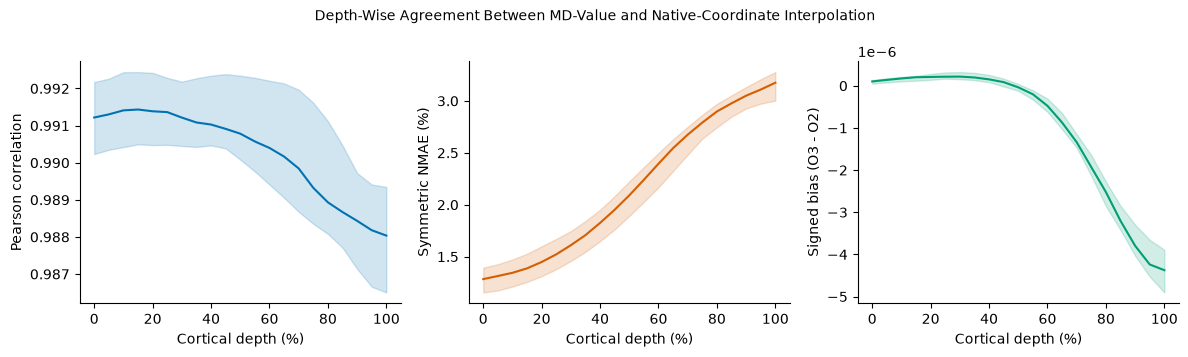

In [3]:
def save_figure(fig, name):
    FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_ROOT / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_ROOT / f"{name}.pdf", bbox_inches="tight")
    plt.show()


x = cohort_depth.depth * 100
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
figure_1_metrics = [
    ("pearson_r", "Pearson correlation", "#0072B2"),
    ("snmae_pct", "Symmetric NMAE (%)", "#D55E00"),
    ("mean_bias_o3_minus_o2", "Signed bias (O3 - O2)", "#009E73"),
]
for ax, (metric, label, color) in zip(axes, figure_1_metrics):
    ax.plot(x, cohort_depth[f"{metric}_median"], color=color)
    ax.fill_between(
        x,
        cohort_depth[f"{metric}_q25"],
        cohort_depth[f"{metric}_q75"],
        color=color,
        alpha=0.18,
    )
    ax.set_xlabel("Cortical depth (%)")
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(
    "Depth-Wise Agreement Between MD-Value and Native-Coordinate Interpolation",
    fontsize=10,
)
fig.tight_layout()
save_figure(fig, "depth_wise_agreement")

## Figure 2: Preservation of Cross-Subject MD Variation Across Interpolation Orders

The ratio is

`median_subject(abs(F3 - F2)) / SD_subject((F2 + F3) / 2)`.

It is an interpretation scale for method difference relative to
between-subject variation, not a significance threshold.

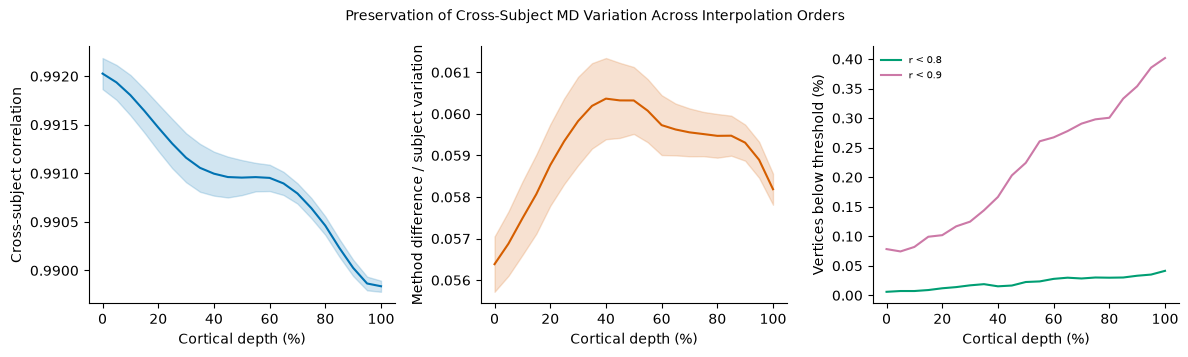

In [4]:
cross_summary = cross_subject.groupby("depth", as_index=False).agg(
    correlation_median=("correlation_median", "median"),
    correlation_q25=("correlation_median", lambda values: values.quantile(0.25)),
    correlation_q75=("correlation_median", lambda values: values.quantile(0.75)),
    pct_below_0_8=("pct_below_0_8", "median"),
    pct_below_0_9=("pct_below_0_9", "median"),
)
ratio_summary = variation_ratio.groupby("depth", as_index=False).agg(
    ratio_median=("ratio_median", "median"),
    ratio_q25=("ratio_median", lambda values: values.quantile(0.25)),
    ratio_q75=("ratio_median", lambda values: values.quantile(0.75)),
)
x = cross_summary.depth * 100
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
axes[0].plot(x, cross_summary.correlation_median, color="#0072B2")
axes[0].fill_between(
    x,
    cross_summary.correlation_q25,
    cross_summary.correlation_q75,
    color="#0072B2",
    alpha=0.18,
)
axes[0].set_ylabel("Cross-subject correlation")
axes[1].plot(x, ratio_summary.ratio_median, color="#D55E00")
axes[1].fill_between(
    x,
    ratio_summary.ratio_q25,
    ratio_summary.ratio_q75,
    color="#D55E00",
    alpha=0.18,
)
axes[1].set_ylabel("Method difference / subject variation")
axes[2].plot(x, cross_summary.pct_below_0_8, label="r < 0.8", color="#009E73")
axes[2].plot(x, cross_summary.pct_below_0_9, label="r < 0.9", color="#CC79A7")
axes[2].set_ylabel("Vertices below threshold (%)")
axes[2].legend(frameon=False, fontsize=7)
for ax in axes:
    ax.set_xlabel("Cortical depth (%)")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(
    "Preservation of Cross-Subject MD Variation Across Interpolation Orders",
    fontsize=10,
)
fig.tight_layout()
save_figure(fig, "cross_subject_preservation")

## Figure 3: Dependence of Interpolation-Order Differences on Spatial Group Size

Spatial group membership was generated from template-surface adjacency
within annotation regions and is shared by both methods. The regional
mean is shown as a separate category.

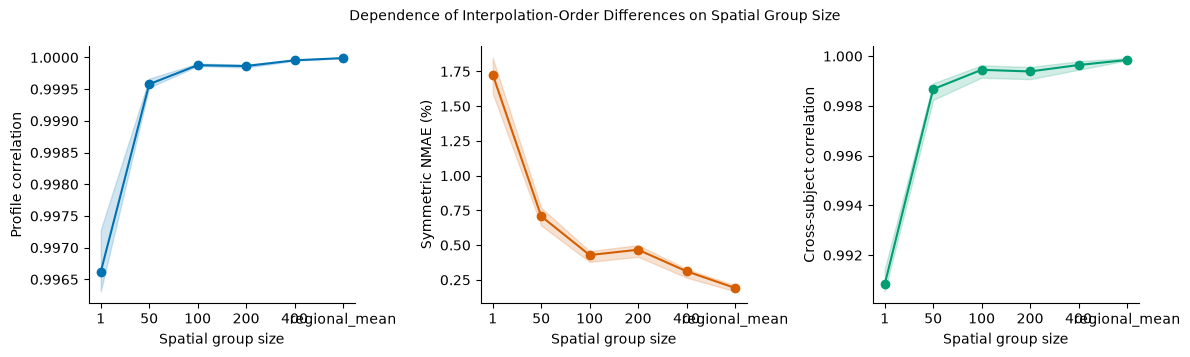

In [5]:
group_summary = group_subject.groupby("group_size", as_index=False).agg(
    profile_correlation_median=("profile_correlation_median", "median"),
    profile_correlation_q25=("profile_correlation_median", lambda values: values.quantile(0.25)),
    profile_correlation_q75=("profile_correlation_median", lambda values: values.quantile(0.75)),
    profile_snmae_median=("profile_snmae_median", "median"),
    profile_snmae_q25=("profile_snmae_median", lambda values: values.quantile(0.25)),
    profile_snmae_q75=("profile_snmae_median", lambda values: values.quantile(0.75)),
)
cross_group_summary = group_cross.groupby(
    "group_size", as_index=False
).agg(
    cross_subject_correlation_median=(
        "cross_subject_correlation_median",
        "median",
    ),
    cross_subject_correlation_q25=(
        "cross_subject_correlation_median",
        lambda values: values.quantile(0.25),
    ),
    cross_subject_correlation_q75=(
        "cross_subject_correlation_median",
        lambda values: values.quantile(0.75),
    ),
)
group_plot = group_summary.merge(cross_group_summary, on="group_size")
group_order = ["1", "50", "100", "200", "400", "regional_mean"]
group_plot["group_size"] = pd.Categorical(
    group_plot.group_size,
    categories=group_order,
    ordered=True,
)
group_plot = group_plot.sort_values("group_size")
x = range(len(group_plot))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
panels = [
    ("profile_correlation", "Profile correlation", "#0072B2"),
    ("profile_snmae", "Symmetric NMAE (%)", "#D55E00"),
    ("cross_subject_correlation", "Cross-subject correlation", "#009E73"),
]
for ax, (prefix, label, color) in zip(axes, panels):
    median = group_plot[f"{prefix}_median"]
    q25 = group_plot[f"{prefix}_q25"]
    q75 = group_plot[f"{prefix}_q75"]
    ax.plot(list(x), median, marker="o", color=color)
    ax.fill_between(list(x), q25, q75, color=color, alpha=0.18)
    ax.set_ylabel(label)
    ax.set_xticks(list(x))
    ax.set_xticklabels(group_plot.group_size)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes:
    ax.set_xlabel("Spatial group size")
fig.suptitle(
    "Dependence of Interpolation-Order Differences on Spatial Group Size",
    fontsize=10,
)
fig.tight_layout()
save_figure(fig, "group_size_comparison")

## 50% depth difference maps

These are subject-level median maps of `O3-Coordinate - O2-Column` at
50% cortical depth. They are generated by Python and can be loaded as
generic FreeSurfer overlays on the corresponding `fsaverage` surface.

In [6]:
difference_maps = sorted(FIGURE_ROOT.glob("*depth50_o3_minus_o2.mgh"))
display(pd.DataFrame({"freeview_overlay": [str(path) for path in difference_maps]}))

,freeview_overlay
0,/mnt/newStor/paros/paros_WORK/xintong/results/...
1,/mnt/newStor/paros/paros_WORK/xintong/results/...


## Preservation of Local Spatial Structure

Adjacent vertices are defined by edges of the fsaverage white-surface
mesh. The supplementary nearby-versus-distant comparison uses the
fixed deterministic pair sampling recorded by the Python script.
Lower adjacent-vertex difference means a smoother map; it is not by
itself evidence of greater accuracy.

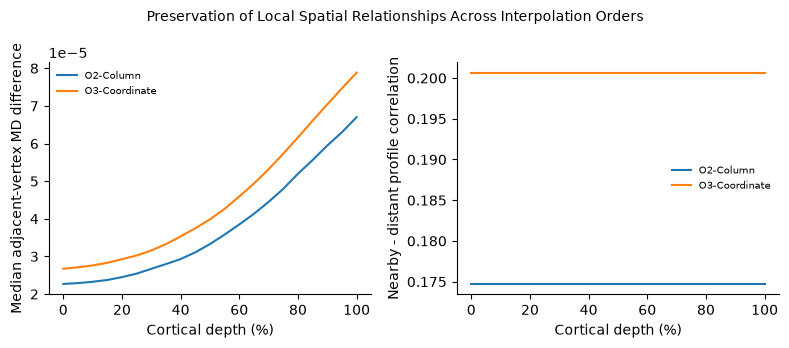

In [7]:
spatial_summary = spatial_structure.groupby("depth", as_index=False).agg(
    o2_adjacent=("o2_adjacent_difference_median", "median"),
    o3_adjacent=("o3_adjacent_difference_median", "median"),
    o2_near_minus_distant=("nearby_minus_distant_o2", "median"),
    o3_near_minus_distant=("nearby_minus_distant_o3", "median"),
)
x = spatial_summary.depth * 100
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True)
axes[0].plot(x, spatial_summary.o2_adjacent, label="O2-Column")
axes[0].plot(x, spatial_summary.o3_adjacent, label="O3-Coordinate")
axes[0].set_ylabel("Median adjacent-vertex MD difference")
axes[0].legend(frameon=False, fontsize=7)
axes[1].plot(
    x,
    spatial_summary.o2_near_minus_distant,
    label="O2-Column",
)
axes[1].plot(
    x,
    spatial_summary.o3_near_minus_distant,
    label="O3-Coordinate",
)
axes[1].set_ylabel("Nearby - distant profile correlation")
axes[1].legend(frameon=False, fontsize=7)
for ax in axes:
    ax.set_xlabel("Cortical depth (%)")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(
    "Preservation of Local Spatial Relationships Across Interpolation Orders",
    fontsize=10,
)
fig.tight_layout()
save_figure(fig, "spatial_structure_preservation")

## Supplementary Comparison With Standard FreeSurfer Surface Resampling

O2-FS is a sensitivity baseline only. It is not included in the main
O2-Column versus O3-Coordinate decision.

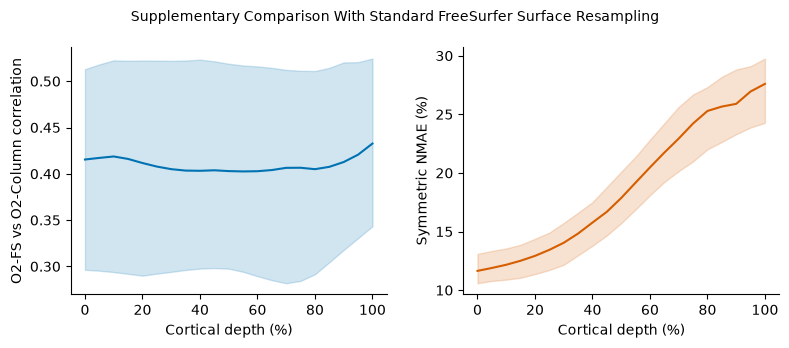

,subject,hemisphere,n_regions,regional_profile_correlation_median,regional_profile_mae_median,regional_profile_snmae_median
0,D0050,lh,34,0.998846,0.000009,1.285733
1,D0050,rh,34,0.999553,0.000010,1.363739
2,D0065,lh,34,0.998941,0.000014,1.810704
3,D0065,rh,34,0.999139,0.000014,1.762756
4,D0086,lh,34,0.999256,0.000011,1.432167


In [8]:
x = o2fs_summary.depth * 100
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True)
axes[0].plot(x, o2fs_summary.pearson_r_median, color="#0072B2")
axes[0].fill_between(
    x,
    o2fs_summary.pearson_r_q25,
    o2fs_summary.pearson_r_q75,
    color="#0072B2",
    alpha=0.18,
)
axes[0].set_ylabel("O2-FS vs O2-Column correlation")
axes[1].plot(x, o2fs_summary.snmae_pct_median, color="#D55E00")
axes[1].fill_between(
    x,
    o2fs_summary.snmae_pct_q25,
    o2fs_summary.snmae_pct_q75,
    color="#D55E00",
    alpha=0.18,
)
axes[1].set_ylabel("Symmetric NMAE (%)")
for ax in axes:
    ax.set_xlabel("Cortical depth (%)")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(
    "Supplementary Comparison With Standard FreeSurfer Surface Resampling",
    fontsize=10,
)
fig.tight_layout()
save_figure(fig, "o2fs_vs_o2column")
display(o2fs_regional.head())

## Saved tables and change log

Reused: existing O2-Column/O3-Coordinate profiles, validated target
mappings, and the common 30-subject manifest.

Recalculated in Python: common validity QC, depth-wise Pearson/MAE/
RMSE/bias/sNMAE, profile metrics, cross-subject metrics, the updated
method-difference ratio, fixed-group metrics, and 50% difference maps.

Skipped here: all volume sampling, surface mapping, profile generation,
and other expensive vertex-level calculations. Priority-2 analyses such
as O2-FS sensitivity and additional spatial-smoothness summaries remain
supplementary and do not block the primary comparison.

This notebook is summary-only. The expensive calculations are kept in
the comparison Python modules in this directory.

In [9]:
summary_files = sorted(METRICS_ROOT.glob("*.csv"))
display(decision_summary)
display(pd.DataFrame({"saved_summary_table": [str(path) for path in summary_files]}))

,analysis_level,main_metric,cohort_result,interpretation
0,QC,Common valid percentage,92.18631364363227,Percentage of template vertices eligible for b...
1,Individual column,Profile correlation,0.9966254681348801,Agreement across the 21-depth profile
2,Individual column,Symmetric NMAE at 50% depth,2.090382765091698,Method difference relative to typical MD magni...
3,Cross-subject,Cross-subject correlation at 50% depth,0.9913171454674108,Preservation of subject ordering at matched ve...
4,Cross-subject,Difference / subject variation at 50% depth,0.0587125830352306,Method difference relative to between-subject ...
5,Spatial groups,Symmetric NMAE by group size,See spatial_group_subject_metrics.csv,Whether method differences decrease with avera...
6,Spatial structure,Nearby minus distant profile correlation,0.17472264170646667,Whether O2-Column retains local spatial relati...


,saved_summary_table
0,/mnt/newStor/paros/paros_WORK/xintong/results/...
1,/mnt/newStor/paros/paros_WORK/xintong/results/...
2,/mnt/newStor/paros/paros_WORK/xintong/results/...
3,/mnt/newStor/paros/paros_WORK/xintong/results/...
4,/mnt/newStor/paros/paros_WORK/xintong/results/...
5,/mnt/newStor/paros/paros_WORK/xintong/results/...
6,/mnt/newStor/paros/paros_WORK/xintong/results/...
7,/mnt/newStor/paros/paros_WORK/xintong/results/...
8,/mnt/newStor/paros/paros_WORK/xintong/results/...
9,/mnt/newStor/paros/paros_WORK/xintong/results/...
